**INTRODUCCIÓN**

El objetivo de este trabajo es diseñar y comparar estimadores de amplitud (â₁) y frecuencia (Ω̂₁) de una señal senoidal contaminada con ruido gaussiano, usando la Transformada de Fourier ventaneada con diferentes ventanas. Se observó cómo el tipo de ventana utilizada afecta el compromiso entre sesgo y varianza de cada estimador, bajo dos situaciones de señal-ruido (SNR = 3 dB y SNR = 10 dB). Las ventanas comparadas son: rectangular, flat-top, Blackman-Harris y Hann.

Se generaron 200 realizaciones de N=1000 muestras de la señal senoidal, con amplitud $\sqrt{2}$ (potencia unitaria) y $ \Omega_1=\Omega_0+f_r\frac{2\pi}{N}, \qquad f_r\sim\mathcal{U}(-2,2), $ donde f_r introduce una incertidumbre en la frecuencia real de hasta $\pm 2$ bines respecto a $\pi/2$. La varianza del ruido se calculó a partir del SNR deseado, despejando:$$ \sigma^2= \frac{P_{\mathrm{señal}}}{10^{\mathrm{SNR}/10}}. $$

In [7]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy import signal

np.random.seed(1)
fs=1000
A0= np.sqrt(2)
N=1000
deltaf=fs/N 
R=200
fr =np.random.uniform(-2,2,R)
omega0= 2*np.pi*(N/4)/N  #rad/muestra
omega= omega0+ fr * (2*np.pi)/(N)  #rad/muestra
#la varianza del ruido normal sale de los SNR . despejo la potencia y se calcula
Psen= (A0**2)/2 #porq es de 1W
frec=deltaf*np.arange(N)[:N//2] #normalizada  (en muestras)
frechz = frec*(2*np.pi)*deltaf
k0=N//4

Para cada ventana se calculó:

*Amplitud:*
$$ \hat{a}_1= \frac{2\left|X_w(\Omega_0)\right|}{GC}, $$
evaluando la FFT ventaneada exactamente en el bin $ k_0=\frac{N}{4}, $ normalizada por la ganancia coherente GC de cada ventana y corregida por el factor 2 propio de la simetría del espectro completo de una señal real.

*Frecuencia:*
$$ \hat{\Omega}_1= \underset{\Omega\in[0,N/2)}{\operatorname{arg\,max}} \left|X_w(\Omega)\right|, $$
limitando la búsqueda a la mitad positiva del espectro para evitar seleccionar el pico espejado.

Sobre las 200 realizaciones se estimó el sesgo (media - valor real) y la varianza muestral de cada estimador.

In [8]:
def funcion_sen( A0 ,N, Pr,R, fr, omega) : 
    nn= (np.arange(0,N)).reshape(1, N)
    rr=omega.reshape(R, 1)

    desvio= np.sqrt(Pr)
    ruidonormal= np.random.normal(0,desvio,size=(R, N))
    vector=(nn *rr)
    xx=  A0 * np.sin(vector) + ruidonormal
    
    return xx

def ventaneo(xx, ww):
    ventaneada = xx*ww
    return ventaneada

#estimadores 
def estimador_energia(xx, w, N, k0):
    ventana = ventaneo(xx,w)
    Xventana= (np.fft.fft(ventana, axis=1))/N
    Xventana_k0 = Xventana[:,k0]
    GC= np.sum(w)/N
    estimador1= 2*np.abs(Xventana_k0)/(GC)
    
    return estimador1

def estimador_frecuencia(xx,w,N, deltaf):
    ventana = ventaneo(xx,w)
    Xventana= (np.fft.fft(ventana, axis=1))[:N//2]/N
    modulo= np.abs(Xventana)
    indice= np.argmax(modulo, axis=1) #en muestras
    for i in range(len(indice)):
        if indice[i]>=N/2:
            indice[i]=indice[i]-N//2
    estimador2= 2*np.pi*indice/N   # en rad/muestra

    return estimador2

In [9]:
#ventanas
cuadrada = np.ones(N)
blackman = signal.windows.blackmanharris(N) 
hann = signal.windows.hann(N)
flattop= signal.windows.flattop(N)

#fft de las ventanas
FFTcuad=np.abs(np.fft.fft(cuadrada)/N)
FFTblack= np.abs(np.fft.fft(blackman)/N)
FFThann= np.abs(np.fft.fft(hann)/N)
FFTflat= np.abs(np.fft.fft(flattop)/N)

FFTcuadDB = 20 * np.log10(FFTcuad + 1e-20)
FFTblackDB = 20 * np.log10(FFTblack + 1e-20)
FFThannDB = 20 * np.log10(FFThann + 1e-20)
FFTflatDB = 20 * np.log10(FFTflat + 1e-20)

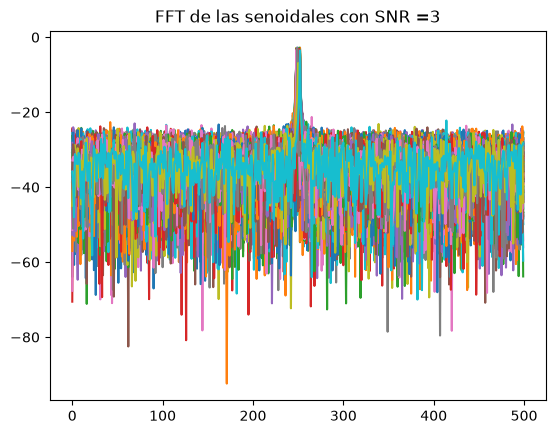


      |AMPLITUD|     

        | Sesgo   |   Varianza     
cuadrada|-0.949317|0.191735
blackman|-0.537914|0.140272
flattop |-0.141885|0.026550
 hann   |-0.756495|0.232303

      |FRECUENCIA|     

        | Sesgo     |   Varianza     
cuadrada|-0.00000000 |0.00006790
blackman|-0.00003142|0.00006652
flattop |0.00018850 |0.00006550
 hann   |-0.00094248 |0.00006623


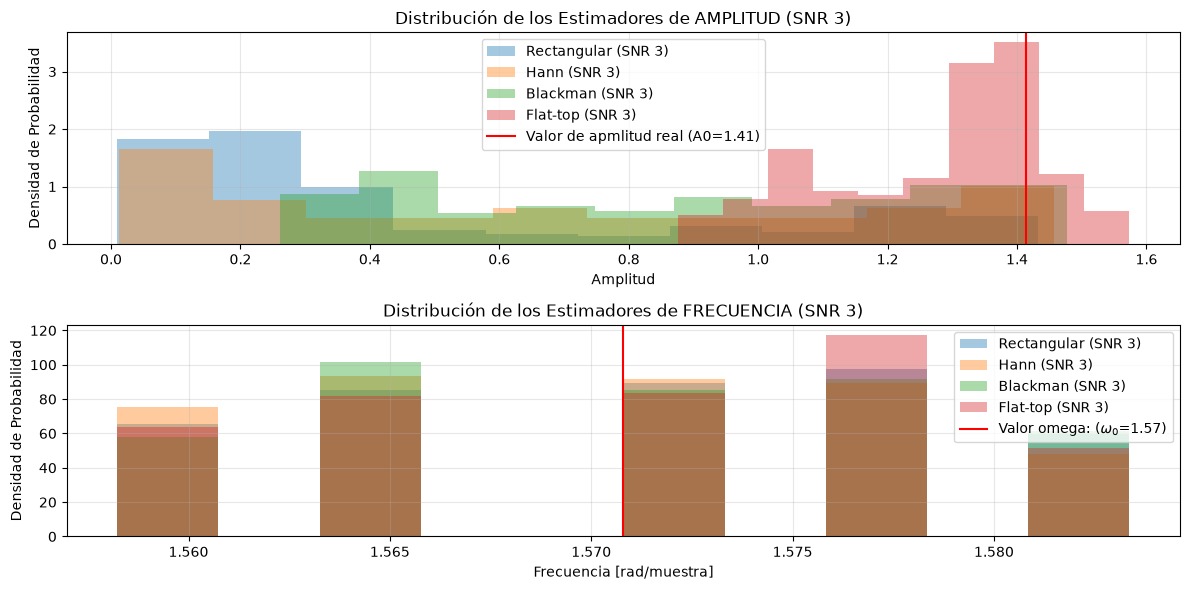

In [10]:
#PARA SNR = 3
SNR3=3
Pr3 = Psen / (10**(SNR3/10))
#fft de las senoidales
senoidal3=funcion_sen(A0, N, Pr3, R, fr,omega)
FFTsenoidal3 =(np.fft.fft(senoidal3, axis=1).T)[:N//2]/N
MAGFFT3=np.abs(FFTsenoidal3)
MAGFFT_DB3= 10*np.log10(MAGFFT3**2 / Psen)

#estimadores de amplitud
ampcuad3= estimador_energia(senoidal3, cuadrada, N, k0)
amphann3= estimador_energia(senoidal3, hann, N, k0)
ampblack3= estimador_energia(senoidal3, blackman, N, k0)
ampflat3= estimador_energia(senoidal3, flattop, N, k0)

#estimadores de frecuencia
freccuad3=estimador_frecuencia(senoidal3, cuadrada, N, deltaf)
frechann3= estimador_frecuencia(senoidal3, hann, N, deltaf)
frecblack3=estimador_frecuencia(senoidal3, blackman, N, deltaf)
frecflat3 =estimador_frecuencia(senoidal3, flattop, N, deltaf)

#sesgos y varianzas
sesgoampcuad3  = np.mean(ampcuad3)  - A0
sesgoamphann3  = np.mean(amphann3)  - A0
sesgoampblack3 = np.mean(ampblack3) - A0
sesgoampflat3  = np.mean(ampflat3)  - A0

varampcuad3= np.var(ampcuad3)
varamphann3= np.var(amphann3)
varampblack3= np.var(ampblack3)
varampflat3= np.var(ampflat3)

sesgofreccuad3  = np.mean(freccuad3)  - omega0
sesgofrechann3  = np.mean(frechann3)  - omega0
sesgofrecblack3 = np.mean(frecblack3) - omega0
sesgofrecflat3  = np.mean(frecflat3) - omega0

varfreccuad3=np.var(freccuad3)
varfrechann3=np.var(frechann3)
varfrecblack3=np.var(frecblack3)
varfrecflat3=np.var(frecflat3)

#ploteo las senoidales
plt.figure()
plt.plot(frec, MAGFFT_DB3)
plt.title("FFT de las senoidales con SNR =3")
plt.show()

#imprimo los sesgos y varianzas
print("\n      |AMPLITUD|     \n")
print("        | Sesgo   |   Varianza     ")
print(f"cuadrada|{sesgoampcuad3:.6f}|{varampcuad3:.6f}")
print(f"blackman|{sesgoampblack3:.6f}|{varampblack3:.6f}")
print(f"flattop |{sesgoampflat3:.6f}|{varampflat3:.6f}")
print(f" hann   |{sesgoamphann3:.6f}|{varamphann3:.6f}")


print("\n      |FRECUENCIA|     \n")
print("        | Sesgo     |   Varianza     ")
print(f"cuadrada|{sesgofreccuad3:.8f} |{varfreccuad3:.8f}")
print(f"blackman|{sesgofrecblack3:.8f}|{varfrecblack3:.8f}")
print(f"flattop |{sesgofrecflat3:.8f} |{varfrecflat3:.8f}")
print(f" hann   |{sesgofrechann3:.8f} |{varfrechann3:.8f}")

#histogramas
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.hist(ampcuad3, alpha=0.4, label='Rectangular (SNR 3)', density=True)
plt.hist(amphann3,  alpha=0.4, label='Hann (SNR 3)', density=True)
plt.hist(ampblack3, alpha=0.4, label='Blackman (SNR 3)', density=True)
plt.hist(ampflat3,  alpha=0.4, label='Flat-top (SNR 3)', density=True)
plt.axvline(A0, color='red', label=f'Valor de apmlitud real (A0={A0:.2f})')
plt.title('Distribución de los Estimadores de AMPLITUD (SNR 3)')
plt.xlabel('Amplitud')
plt.ylabel('Densidad de Probabilidad')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.hist(freccuad3, alpha=0.4, label='Rectangular (SNR 3)', density=True)
plt.hist(frechann3,  alpha=0.4, label='Hann (SNR 3)', density=True)
plt.hist(frecblack3,  alpha=0.4, label='Blackman (SNR 3)', density=True)
plt.hist(frecflat3, alpha=0.4, label='Flat-top (SNR 3)', density=True)
plt.axvline(omega0, color='red', label=f'Valor omega: ($\omega_0$={omega0:.2f})')
plt.title('Distribución de los Estimadores de FRECUENCIA (SNR 3)')
plt.xlabel('Frecuencia [rad/muestra]')
plt.ylabel('Densidad de Probabilidad')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**ANALISI DE LOS RESULTADOS para SNR=3**

*Estimación de amplitud*

El orden de sesgo (de peor a mejor) es: rectangular (-0.95) > hann (-0.76) > Blackman-Harris (-0.54) > flat-top (-0.14). Esto sigue directamente el ancho del lóbulo principal de cada ventana: cuanto más angosto el lóbulo, más rápido cae la magnitud medida en el bin fijo $\Omega_0$ cuando la frecuencia real $\Omega_1$ se aleja de él, así que rectangular (el lóbulo más angosto de las cuatro) es la que más amplitud 'pierde' en promedio.

En el histograma se ve esto con claridad: la distribución de rectangular está pegada contra el eje izquierdo, entre 0 y ~0.5, muy lejos de la línea roja de A₀=1.41. Hann tiene una distribución más ancha y aplanada, extendida desde 0 hasta casi 1.6 (es justamente la de mayor varianza (0.232)). Blackman-Harris se concentra más hacia el centro y derecha del rango (0.4-1.4 aprox.), y flat-top es la única que se agrupa de forma más compacta cerca del valor real, con una ligera tendencia hacia la izquierda.

*Estimación de frecuencia*

En este caso las cuatro ventanas se comportan de forma casi idéntica: sesgos del orden de 10⁻⁴ rad/muestra (prácticamente despreciables  comparado con la escala de  $\Omega_0 =$ 1.57) y varianzas todas al rededor de a 6.5-6.7×10⁻⁵. En el histograma se ve que las cuatro ventanas concentran sus estimaciones en los mismos 3-4 bines discretos alrededor de $\omega_0$, sin demasiadas dispersiones. Esto indica que, aun con SNR=3 dB, el pico espectral de la señal sigue siendo lo suficientemente grande como para que el argmax no tome un pico de ruido.

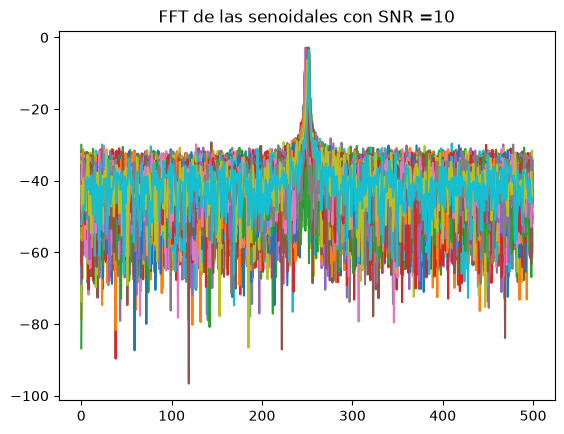


      |AMPLITUD|     

        | Sesgo   |   Varianza     
cuadrada|-0.951723|0.195938
blackman|-0.533876|0.142997
flattop |-0.136422|0.025611
 hann   |-0.754701|0.237636

      |FRECUENCIA|     

        | Sesgo     |   Varianza     
cuadrada|-0.00072257 |0.00006758
blackman|-0.00106814|0.00006558
flattop |-0.00018850 |0.00006313
 hann   |-0.00062832 |0.00006632


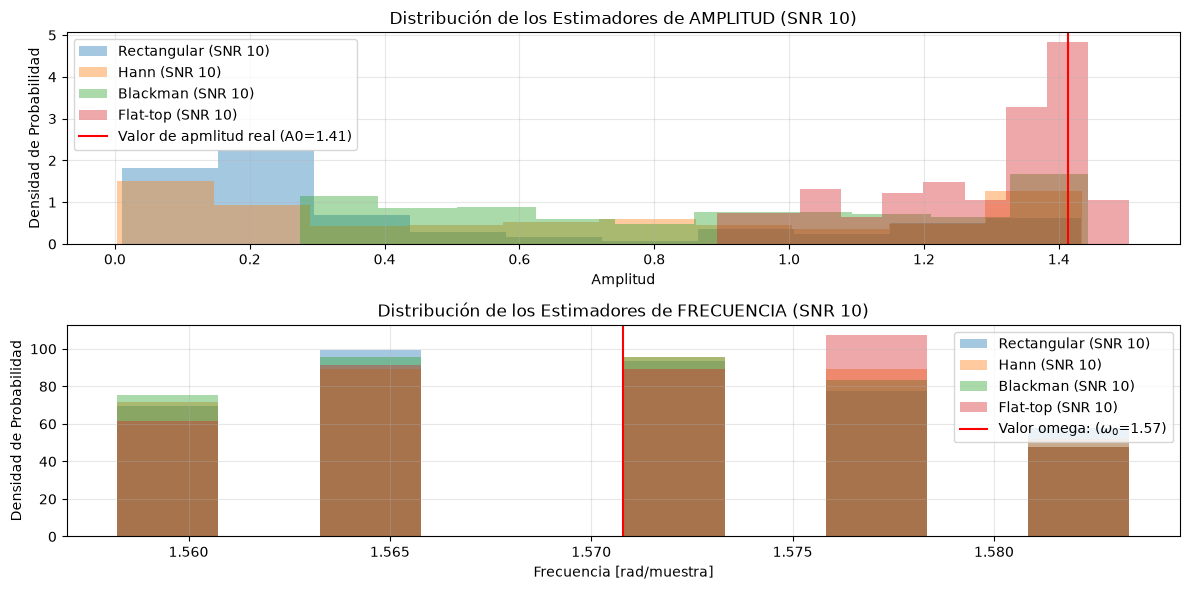

In [11]:
# PARA SNR = 10
SNR10 = 10
Pr10 = Psen / (10**(SNR10/10))

# fft de las senoidales
senoidal10 = funcion_sen(A0, N, Pr10, R, fr, omega)
FFTsenoidal10 = (np.fft.fft(senoidal10, axis=1).T)[:N//2]/N
MAGFFT10 = np.abs(FFTsenoidal10)
MAGFFT_DB10 = 10*np.log10(MAGFFT10**2 / Psen)

# estimadores de amplitud
ampcuad10 = estimador_energia(senoidal10, cuadrada, N, k0)
amphann10 = estimador_energia(senoidal10, hann, N, k0)
ampblack10 = estimador_energia(senoidal10, blackman, N, k0)
ampflat10 = estimador_energia(senoidal10, flattop, N, k0)

# estimadores de frecuencia
freccuad10 = estimador_frecuencia(senoidal10, cuadrada, N, deltaf)
frechann10 = estimador_frecuencia(senoidal10, hann, N, deltaf)
frecblack10 = estimador_frecuencia(senoidal10, blackman, N, deltaf)
frecflat10 = estimador_frecuencia(senoidal10, flattop, N, deltaf) # *Nota: mantiene el nombre original 'freckflat'

# sesgos y varianzas
sesgoampcuad10  = np.mean(ampcuad10)  - A0
sesgoamphann10  = np.mean(amphann10)  - A0
sesgoampblack10 = np.mean(ampblack10) - A0
sesgoampflat10  = np.mean(ampflat10)  - A0

varampcuad10 = np.var(ampcuad10)
varamphann10 = np.var(amphann10)
varampblack10 = np.var(ampblack10)
varampflat10 = np.var(ampflat10)

sesgofreccuad10  = np.mean(freccuad10)  - omega0
sesgofrechann10  = np.mean(frechann10)  - omega0
sesgofrecblack10 = np.mean(frecblack10) - omega0
sesgofrecflat10  = np.mean(frecflat10) - omega0

varfreccuad10 = np.var(freccuad10)
varfrechann10 = np.var(frechann10)
varfrecblack10 = np.var(frecblack10)
varfrecflat10 = np.var(frecflat10)


# ploteo las senoidales
plt.figure()
plt.plot(frec, MAGFFT_DB10)
plt.title("FFT de las senoidales con SNR =10")
plt.show()

# imprimo los sesgos y varianzas
print("\n      |AMPLITUD|     \n")
print("        | Sesgo   |   Varianza     ")
print(f"cuadrada|{sesgoampcuad10:.6f}|{varampcuad10:.6f}")
print(f"blackman|{sesgoampblack10:.6f}|{varampblack10:.6f}")
print(f"flattop |{sesgoampflat10:.6f}|{varampflat10:.6f}")
print(f" hann   |{sesgoamphann10:.6f}|{varamphann10:.6f}")


print("\n      |FRECUENCIA|     \n")
print("        | Sesgo     |   Varianza     ")
print(f"cuadrada|{sesgofreccuad10:.8f} |{varfreccuad10:.8f}")
print(f"blackman|{sesgofrecblack10:.8f}|{varfrecblack10:.8f}")
print(f"flattop |{sesgofrecflat10:.8f} |{varfrecflat10:.8f}")
print(f" hann   |{sesgofrechann10:.8f} |{varfrechann10:.8f}")



#histogramas
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.hist(ampcuad10, alpha=0.4, label='Rectangular (SNR 10)', density=True)
plt.hist(amphann10,  alpha=0.4, label='Hann (SNR 10)', density=True)
plt.hist(ampblack10, alpha=0.4, label='Blackman (SNR 10)', density=True)
plt.hist(ampflat10,  alpha=0.4, label='Flat-top (SNR 10)', density=True)
plt.axvline(A0, color='red', label=f'Valor de apmlitud real (A0={A0:.2f})')
plt.title('Distribución de los Estimadores de AMPLITUD (SNR 10)')
plt.xlabel('Amplitud')
plt.ylabel('Densidad de Probabilidad')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 1, 2)
plt.hist(freccuad10, alpha=0.4, label='Rectangular (SNR 10)', density=True)
plt.hist(frechann10,  alpha=0.4, label='Hann (SNR 10)', density=True)
plt.hist(frecblack10,  alpha=0.4, label='Blackman (SNR 10)', density=True)
plt.hist(frecflat10, alpha=0.4, label='Flat-top (SNR 10)', density=True)
plt.axvline(omega0, color='red', label=f'Valor omega: ($\omega_0$={omega0:.2f})')
plt.title('Distribución de los Estimadores de FRECUENCIA (SNR 10)')
plt.xlabel('Frecuencia [rad/muestra]')
plt.ylabel('Densidad de Probabilidad')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**ANALISIS DE LOS RESULTADOS para SNR=10**

*Estimación de amplitud*

Se mantiene el orden de los sesgos respecto a las ventanas: rectangular (-0.95) > hann (-0.75) > Blackman-Harris (-0.53) > flat-top (-0.14). Con valores similares a los de SNR=3 dB. Las varianzas también son casi iguales, lo cual entra perfectamente dentro de la variabilidad esperable de un experimento con 200 realizaciones

*Estimación de frecuencia*

Los sesgos y varianzas también son del mismo orden que con SNR=3 dB. El ruido reducido no mejora perceptiblemente la precisión del estimador de frecuencia, porque la dispersión que se observa ya está dominada por la cuantización al bin más cercano, no por el ruido.

**ANÁLISIS DE LOS RESULTADOS: comparación**

Se observó que aumentar el SNR de $3$ a $10\text{ dB}$ no produce una mejora apreciable en ninguno de los dos estimadores, para ninguna de las cuatro ventanas. Esto se debe a que la varianza que aporta el ruido a la magnitud de un bin de la FFT es $P_r/N$ (potencia de ruido repartida entre los $N$ bines). Con $P_r \approx 0.50$ ($\text{SNR}=3$) y $P_r \approx 0.10$ ($\text{SNR}=10$), ese aporte es del orden de $0.0001\text{--}0.0005$ (dos a tres órdenes de magnitud menor que las varianzas medidas). Por lo cual, el ruido es secundario frente al efecto dominante: la fuga espectral producida por evaluar siempre el mismo bin fijo $\Omega_0$ mientras la frecuencia real $\Omega_1$ se mueve aleatoriamente hasta 2 bines de distancia. Lo cual también explica por qué el orden entre ventanas que se debe a la geometría del lóbulo principal de cada ventana frente al desplazamiento de frecuencia


**COCNLUSIÓN**

Los resultados confirman el compromiso teórico entre ancho de lóbulo principal y precisión de amplitud: flat-top, con el lóbulo más ancho y plano, logra el menor sesgo y menor varianza en la estimación de amplitud, a costa de ser la de peor resolución espectral (mayor ancho de lóbulo). La ventana rectangular, en el otro extremo, sufre la mayor pérdida de amplitud por fuga espectral. 

A diferencia del estimador de amplitud, el estimador de frecuencia resultó prácticamente independiente de la ventana utilizada, tanto en sesgo como en varianza. Esto se debe a que el argmax selecciona el bin más cercano a la frecuencia real independientemente de la forma del lóbulo principal, por lo que su precisión está limitada por la resolución espectral y no por el tipo de ventaneo para los SNR evaluados (a SNR mucho más bajos, las ventanas con menor nivel de lóbulos secundarios podrían ofrecer mayor robustez frente a picos altos de ruido ya que estos podrian ser seleccionados erroneamente por argmax)